# DoubleSlit with strong wind: when the corner policies are not enough

On Office the $d$ corner policies form a complete basis, so GPI is already optimal at every weight
(notebook 15). Here we use a domain where they are **not** complete: `DoubleSlit` from
`RM/sf-fsa-vi/envs/grid_envs.py` with the wind of `DoubleSlit-v1` ($\pm 3$ rows per step, 7 equally
likely outcomes) and $\gamma = 0.9$. The agent always drifts right and is pushed up and down by the
wind; it ends at the top exit `O1` ($\phi = e_1$) or the bottom exit `O2` ($\phi = e_2$).

For $w$ close to $(\tfrac12, \tfrac12)$ the optimal policy **keeps both exits open** until late,
something neither corner policy $\pi(e_1)$, $\pi(e_2)$ does. As a result the CCS is large (181
policies, computed below with exact OLS).

We compare, at held-out weights, three ways of acting with the same basis:

| policy | action at $s$ |
|---|---|
| **GPI** | $\arg\max_a \max_j \Psi^{\pi_j}(s,a)\cdot w$ |
| **metapolicy** | the best of the base policies' own actions $B(s)$, by restricted policy iteration (fixed point $V_{\mathrm{meta}}$) |
| **$\pi^{\mathrm{hyb}}$** | $\arg\max_{a \in A}\big[\phi(s,a)\cdot w + \gamma\,\mathbb E\, V_{\mathrm{meta}}(s')\big]$ |

1. With the **2 corner policies only**: regret as a function of $w$.
2. With a basis grown in **OLS order** (the corners first, then the CCS policies in the order OLS
   finds them): error vs. number of basis policies $k$.

Everything is exact (transition model with the wind distribution, linear solves). Values at the
start state. Kernel: `okb`.

In [1]:
import heapq
import itertools
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog

SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "RM", "sf-fsa-vi"))
if SF_FSA_VI_ROOT not in sys.path:
    sys.path.insert(0, SF_FSA_VI_ROOT)
from envs.grid_envs import DoubleSlit  # noqa: E402

np.set_printoptions(suppress=True, precision=4)

MAX_WIND, GAMMA = 3, 0.9                 # DoubleSlit-v1's wind
env = DoubleSlit(max_wind=MAX_WIND)
N_ACTIONS, FEAT_DIM = env.a_dim, env.feat_dim
print(f"DoubleSlit: {env.height}x{env.width} grid, {N_ACTIONS} actions (up / right / down, "
      f"always drifting right), d={FEAT_DIM} exits {env.PHI_OBJ_TYPES}, wind +-{MAX_WIND}, gamma={GAMMA}")

DoubleSlit: 21x30 grid, 3 actions (up / right / down, always drifting right), d=2 exits ['O1', 'O2'], wind +-3, gamma=0.9


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [2]:
coords = [env.state_to_coords[i] for i in range(env.s_dim)]
S = len(coords)
TERM = np.array([c in env.object_ids for c in coords])   # the two exits: absorbing, value 0
NONTERM = ~TERM
START = env.coords_to_state[env.initial[0]]
_ROWS = np.arange(S)

P = np.zeros((S, N_ACTIONS, S))          # P[s, a, s']
PHI = np.zeros((S, N_ACTIONS, FEAT_DIM)) # expected phi(s, a, s') over the wind
for i, c in enumerate(coords):
    if TERM[i]:
        continue
    for a in range(N_ACTIONS):
        for ns, p in env.coords_act_transition_distr(c, a):
            P[i, a, env.coords_to_state[ns]] += p
            PHI[i, a] += p * env.features(c, a, ns)
assert np.allclose(P[NONTERM].sum(axis=2), 1.0)
print(f"|S|={S} ({int(NONTERM.sum())} non-terminal), start={coords[START]}, "
      f"{2 * MAX_WIND + 1} equally likely wind outcomes per step")

|S|=535 (533 non-terminal), start=(10, 0), 7 equally likely wind outcomes per step


In [3]:
def value(actions, w):
    return np.linalg.solve(np.eye(S) - GAMMA * P[_ROWS, actions], PHI[_ROWS, actions] @ w)


def sf_state(actions):
    return np.linalg.solve(np.eye(S) - GAMMA * P[_ROWS, actions], PHI[_ROWS, actions])


def q_backup(V, w):
    return PHI @ w + GAMMA * P @ V


def sf_backup(Psi_s):
    return PHI + GAMMA * P @ Psi_s


def policy_iteration(w, max_sweeps=1000):
    pi = np.zeros(S, dtype=int)
    for _ in range(max_sweeps):
        V = value(pi, w)
        Q = q_backup(V, w)
        best = Q.argmax(axis=1)
        new = np.where(Q[_ROWS, pi] >= Q[_ROWS, best] - 1e-12, pi, best)
        if np.array_equal(new, pi):
            return pi, V
        pi = new
    raise RuntimeError("policy iteration did not converge")


class Policy:
    def __init__(self, w, actions):
        self.w, self.actions = w, actions
        self.psi_s = sf_state(actions)
        self.psi_sa = sf_backup(self.psi_s)
        self.psi0 = self.psi_s[START]


def solve_exact(w):
    return Policy(w, policy_iteration(w)[0])


def meta_policy_iteration(w, basis, max_sweeps=500):
    # restricted policy iteration: at each state choose among the base policies' own actions B(s)
    own = np.stack([p.actions for p in basis])
    j = np.argmax(np.stack([p.psi_s @ w for p in basis]), axis=0)
    for _ in range(max_sweeps):
        actions = own[j, _ROWS]
        V = value(actions, w)
        Q = q_backup(V, w)
        Qj = Q[_ROWS[None, :], own]
        best = Qj.argmax(axis=0)
        new = np.where(Qj[j, _ROWS] >= Qj[best, _ROWS] - 1e-12, j, best)
        if np.array_equal(new, j):
            return actions, V, Q
        j = new
    return own[j, _ROWS], V, Q


def three_values(basis, w):
    # exact start-state value of GPI, the metapolicy and pi^hyb, all built from the same basis
    a_gpi = np.stack([p.psi_sa @ w for p in basis]).max(axis=0).argmax(axis=1)
    _, V_meta, Q = meta_policy_iteration(w, basis)          # Q = full-action backup of V_meta
    return (value(a_gpi, w)[START], V_meta[START], value(Q.argmax(axis=1), w)[START])

## Test set and the optimal values

In [4]:
N_TEST = 201
X_TEST = np.linspace(0.0, 1.0, N_TEST)              # w = (x, 1 - x)
TEST = [np.array([x, 1 - x]) for x in X_TEST]
t0 = time.perf_counter()
V_STAR = np.array([policy_iteration(w)[1][START] for w in TEST])
print(f"V*(s0) at {N_TEST} weights in {time.perf_counter() - t0:.0f}s")
POLICIES = ("GPI", "metapolicy", "hyb")


def regrets(basis):
    # relative regret (%) of the three policies at every test weight
    V = np.array([three_values(basis, w) for w in TEST])
    gap = V_STAR[:, None] - V
    gap[gap < 1e-9 * V_STAR[:, None]] = 0.0               # below 1e-9 relative: float noise
    return {name: 100 * gap[:, i] / V_STAR for i, name in enumerate(POLICIES)}

V*(s0) at 201 weights in 161s


## 1. The two corner policies

$V^{\pi(e_i)}(s_0)\cdot w$ is a line in $w$; the optimal value $V^*_w(s_0)$ is their upper envelope
only near the ends. In the middle it lies strictly above both lines: this is where hedging between
the exits pays off and the corner basis is incomplete.

In [5]:
CORNERS = [solve_exact(e) for e in np.eye(FEAT_DIM)]
R2 = regrets(CORNERS)
corner_lines = np.array([[p.psi0 @ w for w in TEST] for p in CORNERS])
best_corner = corner_lines.max(axis=0)

print(f"max gain of V* over the best corner policy: {100 * ((V_STAR - best_corner) / V_STAR).max():.2f}%\n")
print(f"{'':12s} {'mean regret %':>14s} {'max regret %':>13s} {'% weights subopt':>17s}")
for name in POLICIES:
    r = R2[name]
    print(f"{name:12s} {r.mean():14.4f} {r.max():13.3f} {100 * np.mean(r > 1e-4):17.1f}")

max gain of V* over the best corner policy: 20.66%

              mean regret %  max regret %  % weights subopt
GPI                  0.7074         2.519              58.2
metapolicy           0.3170         2.146              54.2
hyb                  0.0005         0.019              14.9


## 2. Growing the basis in OLS order

Exact OLS (corner weights of the current CCS, largest optimistic improvement first, tolerance
$10^{-6}$). Its output order gives a nested sequence of bases: $k = 1$ is $\pi(e_1)$, $k = 2$ adds
$\pi(e_2)$, and from $k = 3$ on come the hedging policies. With $d = 2$ the corner weights are the
breakpoints of the upper envelope of the lines $\psi_i \cdot (x, 1 - x)$, computed directly.

In [6]:
def v_smp(psi_vecs, w):
    return max((v @ w for v in psi_vecs), default=-np.inf)


def corner_weights(psi_vecs):
    # d = 2: w = (x, 1 - x), each policy is the line psi_i.w = psi_i[1] + x (psi_i[0] - psi_i[1]);
    # the corner weights are the breakpoints of the upper envelope of these lines on [0, 1]
    Pm = np.asarray(psi_vecs)
    slope, icpt = Pm[:, 0] - Pm[:, 1], Pm[:, 1]
    xs = {0.0, 1.0}
    for i, j in itertools.combinations(range(len(Pm)), 2):
        if abs(slope[i] - slope[j]) > 1e-12:
            x = (icpt[j] - icpt[i]) / (slope[i] - slope[j])
            if 0 < x < 1:
                y = icpt[i] + slope[i] * x
                if y >= (icpt + slope * x).max() - 1e-10:      # on the envelope
                    xs.add(float(x))
    return [np.array([x, 1 - x]) for x in sorted(xs)]


def estimate_improvement(w, psi_vecs, w_exp):
    res = linprog(c=-w, A_ub=np.array(w_exp), b_ub=[v_smp(psi_vecs, wp) for wp in w_exp],
                  bounds=[(None, None)] * len(w), method="highs")
    return (-res.fun if res.success else np.inf) - v_smp(psi_vecs, w)


def ols(tol=1e-6, max_iterations=500):
    # standard OLS (exact solves), recording the order in which policies enter the CCS
    ccs, W_exp = [], []
    counter = itertools.count()
    heap = [(-np.inf, next(counter), tuple(e)) for e in np.eye(FEAT_DIM)]
    n_queries = 0
    while heap and n_queries < max_iterations:
        _, _, wt = heapq.heappop(heap)
        w = np.array(wt)
        n_queries += 1
        policy = solve_exact(w)
        W_exp.append(w)
        psis = [p.psi0 for p in ccs]
        if psis and policy.psi0 @ w <= v_smp(psis, w) + 1e-9:
            continue
        ccs.append(policy)
        psis.append(policy.psi0)
        heap = [h for h in heap if h[0] == -np.inf]       # re-score every corner of the new CCS
        for wc in corner_weights(psis):
            if any(np.allclose(wc, x, atol=1e-9) for x in W_exp):
                continue
            delta = estimate_improvement(wc, psis, W_exp)
            if delta > tol:
                heapq.heappush(heap, (-delta, next(counter), tuple(wc)))
    return ccs, n_queries

In [7]:
import pickle

K_MAX = 20
# cache of OLS + the regrets for k = 1..K_MAX (~10 min): delete the file or set RECOMPUTE to rerun
RECOMPUTE = False
OLS_CACHE = os.path.join("results", "double_slit_ols.pkl")

if not RECOMPUTE and os.path.exists(OLS_CACHE):
    with open(OLS_CACHE, "rb") as f:
        CCS, n_queries, RK = pickle.load(f)
    print(f"loaded cached OLS + regrets from {OLS_CACHE}")
else:
    t0 = time.perf_counter()
    CCS, n_queries = ols()
    print(f"OLS: CCS of {len(CCS)} policies, {n_queries} queries, {time.perf_counter() - t0:.0f}s")
    t0 = time.perf_counter()
    RK = [regrets(CCS[:k]) for k in range(1, K_MAX + 1)]
    print(f"regrets for k = 1..{K_MAX} in {time.perf_counter() - t0:.0f}s")
    os.makedirs(os.path.dirname(OLS_CACHE), exist_ok=True)
    with open(OLS_CACHE, "wb") as f:
        pickle.dump((CCS, n_queries, RK), f)
print(f"CCS of {len(CCS)} policies, {n_queries} queries")
print("first query weights w_1:", np.round([p.w[0] for p in CCS[:10]], 3), "\n")
print(f"{'k':>3s} " + " ".join(f"{n + ' % subopt':>18s}" for n in POLICIES)
      + "  " + " ".join(f"{n + ' mean regret %':>24s}" for n in POLICIES))
for k, r in enumerate(RK, start=1):
    print(f"{k:>3d} " + " ".join(f"{100 * np.mean(r[n] > 1e-4):18.1f}" for n in POLICIES)
          + "  " + " ".join(f"{r[n].mean():24.5f}" for n in POLICIES))

OLS: CCS of 181 policies, 204 queries, 492s


regrets for k = 1..20 in 134s
CCS of 181 policies, 204 queries
first query weights w_1: [1.    0.    0.5   0.374 0.636 0.314 0.695 0.578 0.443 0.279] 

  k       GPI % subopt metapolicy % subopt       hyb % subopt         GPI mean regret % metapolicy mean regret %        hyb mean regret %
  1               79.1               80.6               79.1                  19.36907                 33.77938                 19.36907
  2               58.2               54.2               14.9                   0.70738                  0.31701                  0.00051
  3               51.7               36.8               13.9                   0.15305                  0.02660                  0.00023
  4               47.3               36.3               10.4                   0.07431                  0.02038                  0.00016
  5               43.3               30.3                6.0                   0.01544                  0.01303                  0.00008
  6               39.8   

## Figures

Same style as notebooks 13-15. Saved to `notes/figures/double_slit_corners.pdf` and
`notes/figures/double_slit_basis_growth.pdf`.

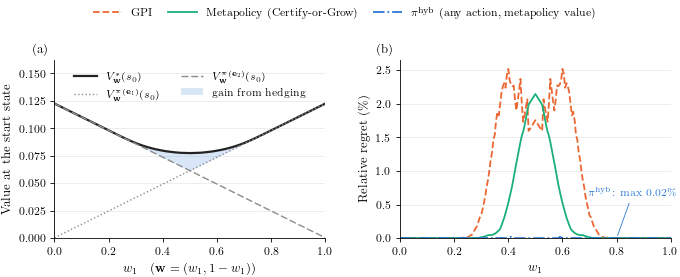

saved ../notes/figures/double_slit_corners.pdf  (TeX rendering: True)


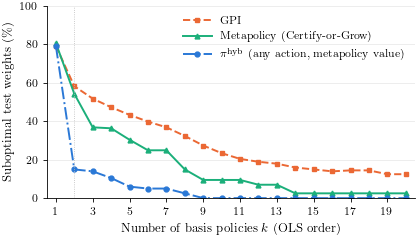

saved ../notes/figures/double_slit_basis_growth.pdf  (TeX rendering: True)


In [8]:
import shutil

os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"
USE_TEX = shutil.which("latex") is not None
PUB_RC = {
    "text.usetex": USE_TEX, "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"], "mathtext.fontset": "cm",
    "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
}
STYLE = {"GPI":        dict(color="#eb6834", ls="--", marker="s"),
         "metapolicy": dict(color="#1baf7a", ls="-",  marker="^"),
         "hyb":        dict(color="#2a78d6", ls="-.", marker="o")}
LEGEND = {"GPI": "GPI", "metapolicy": "Metapolicy (Certify-or-Grow)",
          "hyb": r"$\pi^{\mathrm{hyb}}$ (any action, metapolicy value)"}


def tidy(ax, tag):
    ax.text(-0.02, 1.03, rf"({tag})", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.5)
    ax.set_axisbelow(True)


def save(fig, name):
    out = os.path.join("..", "notes", "figures", name)
    fig.savefig(out)
    plt.show()
    print(f"saved {out}  (TeX rendering: {USE_TEX})")


# ---- figure 1: the two corner policies -------------------------------------------------
with plt.rc_context(PUB_RC):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
    ax = axes[0]
    ax.plot(X_TEST, V_STAR, color="#222222", lw=1.6, label=r"$V^*_{\mathbf w}(s_0)$")
    for i, ls in enumerate((":", (0, (5, 2)))):
        ax.plot(X_TEST, corner_lines[i], color="#8c8c8c", lw=1.0, ls=ls,
                label=rf"$V^{{\pi(\mathbf e_{i + 1})}}_{{\mathbf w}}(s_0)$")
    ax.fill_between(X_TEST, best_corner, V_STAR, color="#2a78d6", alpha=0.18, lw=0,
                    label="gain from hedging")
    ax.set_ylim(0, 1.32 * V_STAR.max())
    ax.set_xlim(0, 1)
    ax.set_xlabel(r"$w_1$  \ \ ($\mathbf w = (w_1, 1 - w_1)$)" if USE_TEX else "w_1")
    ax.set_ylabel(r"Value at the start state")
    ax.legend(loc="upper center", frameon=False, ncol=2, fontsize=7.5, handlelength=2.2)
    tidy(ax, "a")

    ax = axes[1]
    for name in POLICIES:
        st = STYLE[name]
        ax.plot(X_TEST, R2[name], color=st["color"], ls=st["ls"], lw=1.3, label=LEGEND[name])
    ax.annotate(rf"$\pi^{{\mathrm{{hyb}}}}$: max {R2['hyb'].max():.2f}\%" if USE_TEX else "hyb",
                xy=(0.8, 0.0), xytext=(0.86, 0.25 * R2["GPI"].max()), ha="center",
                fontsize=7.5, color=STYLE["hyb"]["color"],
                arrowprops=dict(arrowstyle="-", color=STYLE["hyb"]["color"], lw=0.6))
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r"$w_1$")
    ax.set_ylabel(r"Relative regret (\%)" if USE_TEX else "Relative regret (%)")
    tidy(ax, "b")
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,
               handlelength=2.6, columnspacing=1.4)
    fig.tight_layout(w_pad=2.0)
    save(fig, "double_slit_corners.pdf")

# ---- figure 2: suboptimal test weights vs number of basis policies (OLS order) ---------------
ks = np.arange(1, K_MAX + 1)
with plt.rc_context(PUB_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6))
    for name in POLICIES:
        st = STYLE[name]
        sub = np.array([100 * np.mean(r[name] > 1e-4) for r in RK])
        ax.plot(ks, sub, color=st["color"], ls=st["ls"], lw=1.4, marker=st["marker"], ms=3.5, label=LEGEND[name])
    ax.set_ylim(0, 100)
    ax.set_ylabel(r"Suboptimal test weights (\%)" if USE_TEX else "Suboptimal test weights (%)")
    ax.set_xticks(ks[::2] if K_MAX > 10 else ks)
    ax.set_xlim(0.5, K_MAX + 0.5)
    ax.set_xlabel(r"Number of basis policies $k$ (OLS order)")
    ax.axvline(2, color="#bbbbbb", lw=0.6, ls=":")          # k = 2: both corners
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.5)
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", frameon=False, handlelength=2.6)
    fig.tight_layout()
    save(fig, "double_slit_basis_growth.pdf")


## Domain figure

The layout, and the actions of the optimal policy at $w = (0.5, 0.5)$ next to the corner policy
$\pi(e_1)$. Saved to `notes/figures/double_slit_domain.pdf` (and copied to `paper/figures/`).


In [9]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, FancyArrowPatch

H, Wd = env.MAP.shape
WALL, UP, RIGHT, DOWN, EXIT = 0, 1, 2, 3, 4
CMAP = ListedColormap(["#4d4d4d", "#2a78d6", "#e9e9e9", "#eb6834", "#1baf7a"])


def action_grid(actions):
    g = np.full((H, Wd), WALL)
    for i, (r, c) in enumerate(coords):
        g[r, c] = EXIT if TERM[i] else 1 + int(actions[i])   # UP=0 -> 1, RIGHT=1 -> 2, DOWN=2 -> 3
    return g


panels = [(np.array([0.5, 0.5]), r"(a) optimal policy, $\mathbf w = (0.5, 0.5)$"),
          (np.array([1.0, 0.0]), r"(b) corner policy $\pi(\mathbf e_1)$")]
r0, c0 = env.initial[0]
with plt.rc_context(PUB_RC):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.55))
    for ax, (w, title) in zip(axes, panels):
        pi, _ = policy_iteration(w)
        ax.imshow(action_grid(pi), cmap=CMAP, vmin=0, vmax=4, interpolation="nearest")
        ax.plot(c0, r0, marker="o", ms=5, color="black")
        ax.annotate(r"$s_0$", (c0, r0), xytext=(c0 + 1.2, r0 + 0.4), fontsize=8, va="center")
        for (r, c), name in zip([env.exit_states[0], env.exit_states[1]], (r"$\mathbf e_1$", r"$\mathbf e_2$")):
            ax.annotate(name, (c, r), xytext=(c - 3.2, r + (1.6 if r == 0 else -1.0)), fontsize=8,
                        color="#11704f", va="center")
        ax.set_title(title, fontsize=9, pad=4)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
    # wind: a vertical double arrow in the left panel
    axes[0].add_patch(FancyArrowPatch((6, 13.5), (6, 6.5), arrowstyle="<->", mutation_scale=8,
                                      color="#222222", lw=0.8))
    axes[0].annotate(r"wind $\pm 3$", (6.6, 10), fontsize=7.5, va="center")
    handles = [Patch(color="#2a78d6", label="up"), Patch(color="#e9e9e9", label="right"),
               Patch(color="#eb6834", label="down"), Patch(color="#1baf7a", label="exit"),
               Patch(color="#4d4d4d", label="wall")]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, frameon=False,
               handlelength=1.2, columnspacing=1.4)
    fig.tight_layout(w_pad=1.5)
    for out in (os.path.join("..", "notes", "figures", "double_slit_domain.pdf"),
                os.path.join("..", "paper", "figures", "double_slit_domain.pdf")):
        fig.savefig(out)
        print("saved", out)


saved ../notes/figures/double_slit_domain.pdf


saved ../paper/figures/double_slit_domain.pdf


## Paper figure

The domain (optimal policy at $w = (0.5, 0.5)$, with the boundary where $\pi(e_1)$ turns up) next to the basis-growth curve. This cell only saves the data to `notes/figures/data/double_slit.npz`; the figure itself is drawn by `plot_double_slit.py` (saved to `notes/figures/double_slit.pdf` and `paper/figures/double_slit.pdf`).


In [10]:
# everything the combined paper figure needs, read by plot_double_slit.py (no recomputation there)
H, Wd = env.MAP.shape
data_dir = os.path.join("..", "notes", "figures", "data")
os.makedirs(data_dir, exist_ok=True)
np.savez(os.path.join(data_dir, "double_slit.npz"),
         map_shape=np.array([H, Wd]), coords=np.array(coords), term=TERM,
         start=np.array(env.initial[0]), exits=np.array([env.exit_states[0], env.exit_states[1]]),
         max_wind=MAX_WIND,
         actions_opt=policy_iteration(np.array([0.5, 0.5]))[0],     # optimal policy at w = (0.5, 0.5)
         actions_e1=CORNERS[0].actions,                            # corner policy pi(e_1)
         ks=np.arange(1, K_MAX + 1),
         **{f"subopt_{n}": np.array([100 * np.mean(r[n] > 1e-4) for r in RK]) for n in POLICIES})
print("saved", os.path.join(data_dir, "double_slit.npz"))


saved ../notes/figures/data/double_slit.npz


In [11]:
%run plot_double_slit.py


saved /Users/guillemmasdemont/Documents/Master/Summer-Research/MORL/notes/figures/double_slit.pdf  (TeX rendering: True)


saved /Users/guillemmasdemont/Documents/Master/Summer-Research/MORL/paper/figures/double_slit.pdf  (TeX rendering: True)


## Reading the result

*(wind $\pm 3$, $\gamma = 0.9$, 201 held-out weights $\mathbf w = (w_1, 1 - w_1)$, exact values at $s_0$.)*

**The corner basis is incomplete here.** Around $w_1 = 0.5$ the optimal policy keeps both exits
open; its value is up to 20.7% above the best corner policy (shaded region in figure 1a), and the
exact CCS needs **181 policies** (OLS, 204 queries).

**With only the 2 corner policies, $\pi^{\mathrm{hyb}}$ is already near-optimal:**

| (k = 2) | mean regret | max regret | weights suboptimal |
|---|---|---|---|
| GPI | 0.71% | 2.52% | 58% |
| metapolicy | 0.32% | 2.15% | 54% |
| $\pi^{\mathrm{hyb}}$ | **0.0005%** | **0.019%** | 15% (all below 0.02%) |

The metapolicy can switch between the two corner policies from state to state, which already
recovers part of the hedging behaviour ($V_{\mathrm{meta}} > \max_j V^{\pi_j}$, unlike on Office);
$\pi^{\mathrm{hyb}}$ then does one full-action improvement step on top of $V_{\mathrm{meta}}$, which
closes almost all of the remaining gap. GPI bootstraps from the single best base policy and cannot
represent the hedge.

**Growing the basis in OLS order** (figure 2): $\pi^{\mathrm{hyb}}$ is optimal on every test weight
from $k = 9$ on, while the metapolicy is still suboptimal on 2.5% and GPI on 12.4% of the weights
at $k = 20$. GPI's error is not monotone in $k$ (e.g. 13.9% → 14.4% from $k = 16$ to 17): adding a
policy can change GPI's choice for the worse. The metapolicy cannot get worse (a larger basis only
adds actions to $B(s)$, so $V_{\mathrm{meta}}$ can only grow); $\pi^{\mathrm{hyb}}$ has no such guarantee
but is monotone here.

**Message for the paper.** On a domain where the $d$ corners are not a complete basis, Certify-or-Grow's
metapolicy plus one $\pi^{\mathrm{hyb}}$ step turns a basis of 2 policies into an
$\varepsilon$-optimal policy (ε ≈ 0.02%) for all weights, where the CCS has 181 policies and GPI
over the same 2 policies loses up to 2.5%.